# Практическая работа 5. Кластеризация k-средних


In [14]:
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs, load_iris
from sklearn.metrics import silhouette_score, adjusted_rand_score

## 1. KMeans для синтетических данных

Создадим данные из 4 групп и выполним кластеризацию с n_clusters=4.

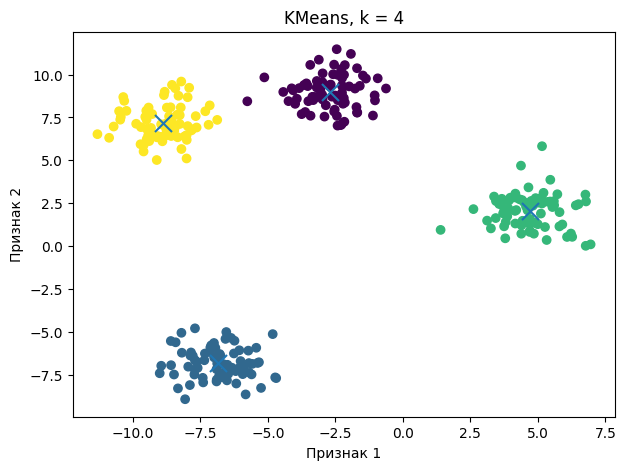

In [15]:
X, y = make_blobs(n_samples=300, centers=4, random_state=42)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=clusters)
plt.scatter(kmeans.cluster_centers_[:, 0],
            kmeans.cluster_centers_[:, 1],
            marker='x', s=150)

plt.title('KMeans, k = 4')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.show()

На графике видно 4 отдельных кластера. Центры кластеров отмечены крестиками.

## 2. Подбор числа кластеров для Iris

Берём только первые два признака, чтобы результат можно было показать на обычном графике.

In [16]:
iris = load_iris()

X_iris = iris.data[:, :2]
y_iris = iris.target

### Метод локтя

Метод локтя помогает выбрать подходящее количество кластеров.

Что мы делаем:
1. По очереди запускаем KMeans для разного количества кластеров: от 1 до 10.
2. Для каждого варианта считаем inertia.
3. Inertia показывает, насколько точки удалены от центров своих кластеров: чем меньше значение, тем компактнее получились кластеры.
4. При увеличении числа кластеров inertia всегда уменьшается, поэтому мы смотрим не на минимальное значение, а на график.
5. Ищем место, где уменьшение inertia начинает заметно замедляться. Это место называют "локтем".

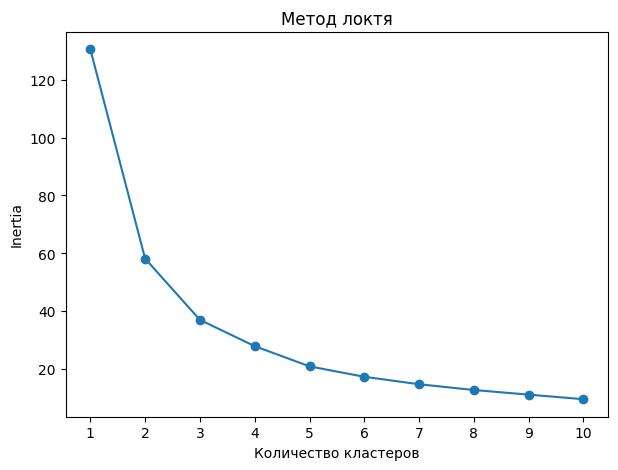

In [17]:
inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_iris)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel('Количество кластеров')
plt.ylabel('Inertia')
plt.title('Метод локтя')
plt.xticks(range(1, 11))
plt.show()

По графику локтя заметный изгиб получается примерно около k = 3.

### Silhouette Score

Silhouette Score тоже помогает выбрать количество кластеров, но оценивает разбиение другим способом.

Что мы делаем:
1. Запускаем KMeans для разного количества кластеров: от 2 до 10.
2. Для каждой точки смотрим, **насколько она близка к точкам своего кластера**.
3. Также смотрим, **насколько она удалена от точек ближайшего другого кластера**.
4. По этим расстояниям рассчитывается Silhouette Score для каждой точки, после чего берётся среднее значение по всем точкам.
5. Чем выше Silhouette Score, тем лучше точки находятся внутри своих кластеров и тем сильнее кластеры отделены друг от друга.


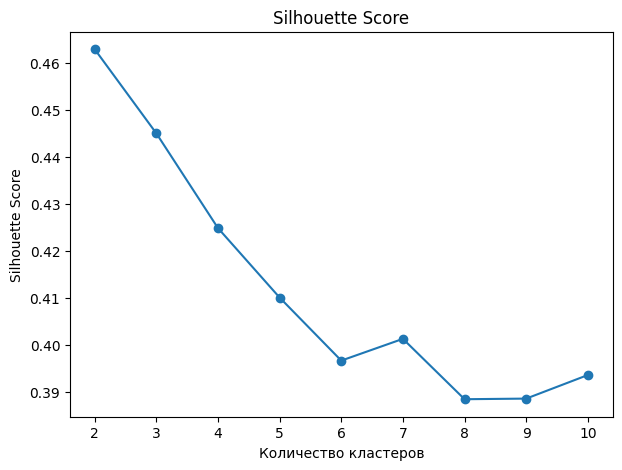

In [18]:
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_iris)
    score = silhouette_score(X_iris, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(7, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel('Количество кластеров')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.xticks(range(2, 11))
plt.show()

In [19]:
for k, score in zip(range(2, 11), silhouette_scores):
    print(k, round(score, 3))

2 0.463
3 0.445
4 0.425
5 0.41
6 0.397
7 0.401
8 0.388
9 0.389
10 0.394


Максимальный Silhouette Score получается при k = 2, а метод локтя показывает примерно k = 3.

Для дальнейшей кластеризации возьмём k = 3, потому что на графике локтя после этого значения уменьшение ошибки становится заметно медленнее.

## 3. Кластеризация Iris с выбранным k

**Как работает KMeans**

KMeans — это алгоритм, который делит точки на `k` групп так, чтобы точки внутри одной группы были как можно ближе друг к другу.

Алгоритм работает по шагам:

1. Сначала выбираются `k` центров кластеров.
2. Для каждой точки считается расстояние до всех центров.
3. Точка относится к тому кластеру, чей центр находится ближе всего.
4. Для каждого кластера пересчитывается новый центр — как среднее значение координат всех точек в этом кластере.
5. Эти шаги повторяются, пока центры почти перестают изменяться.

Расстояние между двумя точками считается так:

$$
d = \sqrt{(x_1-x_2)^2 + (y_1-y_2)^2}
$$

KMeans старается сделать кластеры как можно более компактными. Для этого он уменьшает `inertia` — сумму квадратов расстояний от всех точек до центров их кластеров:

$$
inertia = \sum (x_i - \mu)^2
$$

где `x_i` — точка, а `\mu` — центр её кластера.

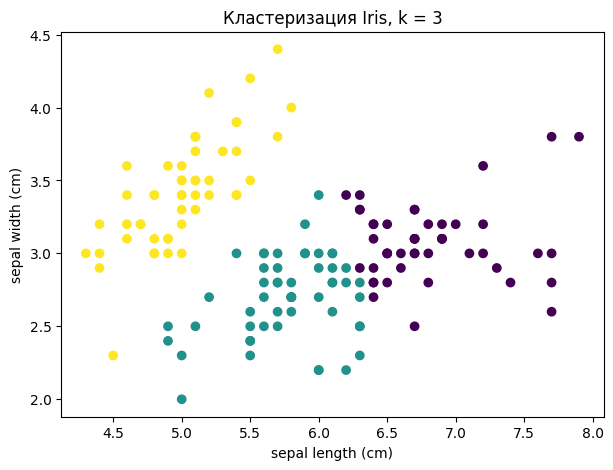

In [20]:
k_opt = 3

kmeans_iris = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
iris_clusters = kmeans_iris.fit_predict(X_iris)

plt.figure(figsize=(7, 5))
plt.scatter(X_iris[:, 0], X_iris[:, 1], c=iris_clusters)

plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title('Кластеризация Iris, k = 3')
plt.show()

Получилось 3 кластера. Один из них отделяется хорошо, а два других частично пересекаются.

## 4. Сравнение с истинными видами Iris

Для сравнения используем adjusted_rand_score.

In [21]:
ari = adjusted_rand_score(y_iris, iris_clusters)

print('Adjusted Rand Score:', round(ari, 3))

Adjusted Rand Score: 0.601


Значение ARI получилось около 0.60. Это значит, что кластеры частично совпадают с настоящими видами ирисов, но не полностью.

## Вывод

KMeans хорошо разделил синтетические данные на 4 группы. Для Iris методы выбора числа кластеров дали немного разные результаты: Silhouette Score был выше при k = 2, а по методу локтя подходящим выглядит k = 3. Для итоговой кластеризации было выбрано k = 3.

## Дополнительное задание. KMeans для Titanic
Используем датасет Titanic из Занятия 1 и возьмём числовые признаки пассажиров.

Берём из Titanic два числовых признака:

- `age` — возраст пассажира;
- `fare` — стоимость билета.

Строки с пропущенными значениями удаляем с помощью `dropna()`.

In [29]:
import seaborn as sns
from sklearn.preprocessing import StandardScaler

df = sns.load_dataset('titanic')

titanic_data = df[['age', 'fare']].dropna()

titanic_data.head()

,age,fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500


Возраст и стоимость билета имеют разные масштабы.

Например, возраст обычно находится примерно в диапазоне от 0 до 80, а стоимость билета может быть больше 500.

Поэтому перед KMeans стандартизируем признаки с помощью `StandardScaler`, чтобы оба признака одинаково влияли на расстояние между точками.

In [30]:
scaler = StandardScaler()
X_titanic = scaler.fit_transform(titanic_data)

Метод локтя помогает выбрать подходящее количество кластеров.

Для каждого `k` от 1 до 10 запускаем KMeans и считаем `inertia`.

`Inertia` показывает, насколько далеко точки находятся от центров своих кластеров. Чем меньше значение, тем компактнее получились кластеры.

При увеличении количества кластеров `inertia` всегда уменьшается, поэтому смотрим на график и ищем место, где уменьшение начинает заметно замедляться. Это место называют "локтем".

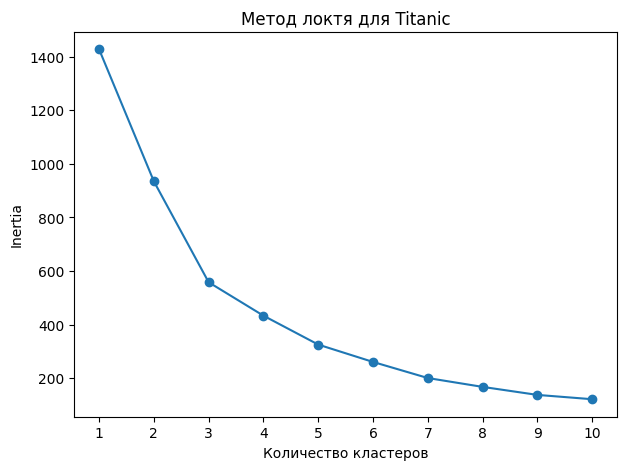

In [31]:
inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_titanic)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel('Количество кластеров')
plt.ylabel('Inertia')
plt.title('Метод локтя для Titanic')
plt.xticks(range(1, 11))
plt.show()

Silhouette Score оценивает, насколько хорошо точки распределены по своим кластерам.

Для каждой точки учитывается:

- насколько она близка к точкам своего кластера;
- насколько она удалена от ближайшего другого кластера.

Чем выше Silhouette Score, тем лучше кластеры отделены друг от друга.

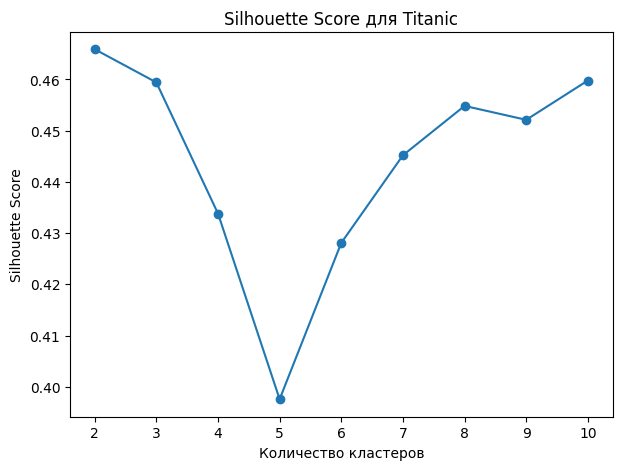

In [32]:
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_titanic)

    score = silhouette_score(X_titanic, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(7, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel('Количество кластеров')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score для Titanic')
plt.xticks(range(2, 11))
plt.show()

По этим значениям можно точно увидеть, при каком количестве кластеров Silhouette Score максимальный.

In [33]:
for k, score in zip(range(2, 11), silhouette_scores):
    print(k, round(score, 3))

2 0.466
3 0.459
4 0.434
5 0.398
6 0.428
7 0.445
8 0.455
9 0.452
10 0.46


In [34]:
k_opt = 3

После выбора количества кластеров запускаем итоговый KMeans.

Каждый пассажир получает номер кластера в зависимости от сочетания его возраста и стоимости билета.

In [35]:
kmeans_titanic = KMeans(
    n_clusters=k_opt,
    random_state=42,
    n_init=10
)

titanic_data = titanic_data.copy()

titanic_data['cluster'] = kmeans_titanic.fit_predict(X_titanic)

Смотрим средние значения возраста и стоимости билета в каждом кластере.

Это помогает понять, чем найденные группы пассажиров отличаются друг от друга.

In [36]:
titanic_data.groupby('cluster').mean().round(2)

,age,fare
cluster,,
0,31.97,222.90
1,21.14,21.64
2,45.12,32.80


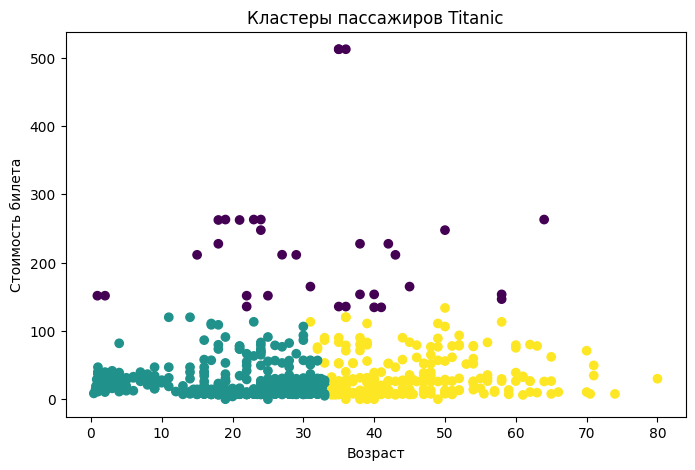

In [37]:
plt.figure(figsize=(8, 5))

plt.scatter(
    titanic_data['age'],
    titanic_data['fare'],
    c=titanic_data['cluster']
)

plt.xlabel('Возраст')
plt.ylabel('Стоимость билета')
plt.title('Кластеры пассажиров Titanic')
plt.show()

На графике каждая точка — это пассажир.

По оси X показан возраст, по оси Y — стоимость билета.

Цвет показывает, к какому кластеру KMeans отнёс пассажира.